In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/kc_house_data.csv")

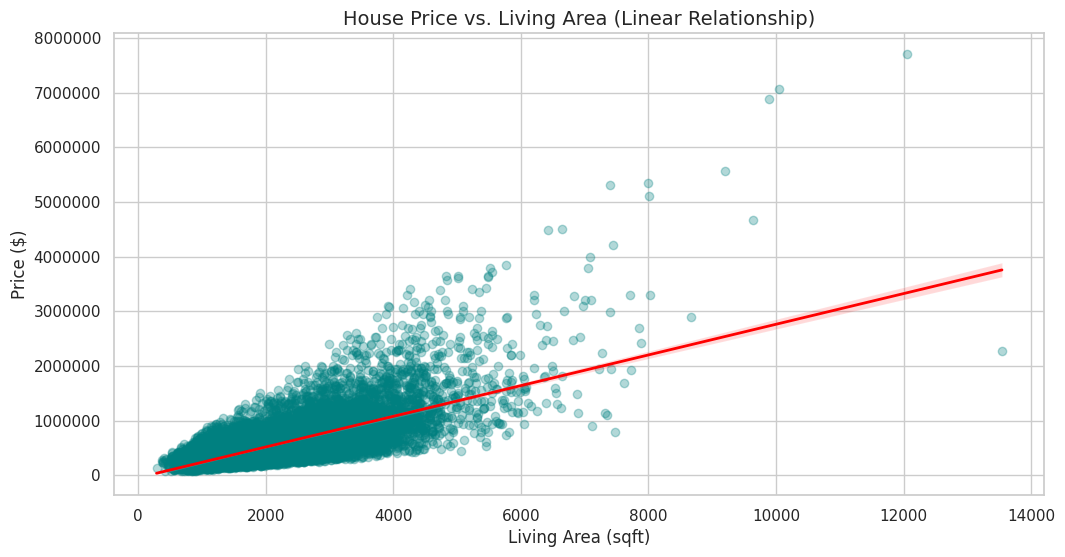

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))
sns.regplot(data=df, x='sqft_living', y='price',
            scatter_kws={'alpha':0.3, 'color': 'teal'},
            line_kws={'color': 'red', 'linewidth': 2})
plt.title('House Price vs. Living Area (Linear Relationship)', fontsize=14)
plt.xlabel('Living Area (sqft)', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.show()

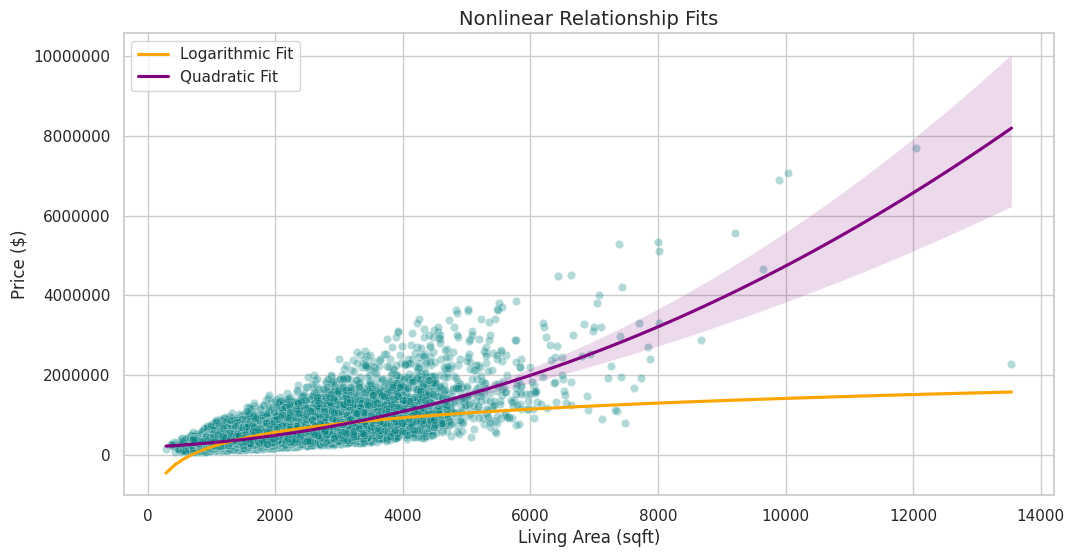

In [4]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='sqft_living', y='price', alpha=0.3, color='teal')
sns.regplot(data=df, x='sqft_living', y='price', logx=True, scatter=False, color='orange', label='Logarithmic Fit')
sns.regplot(data=df, x='sqft_living', y='price', order=2, scatter=False, color='purple', label='Quadratic Fit')
plt.title('Nonlinear Relationship Fits', fontsize=14)
plt.xlabel('Living Area (sqft)', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.legend()
plt.ticklabel_format(style='plain', axis='y')
plt.show()

In [5]:
df['price_per_sqft'] = df['price'] / df['sqft_living']

low_threshold = df['price_per_sqft'].quantile(0.01)
high_threshold = df['price_per_sqft'].quantile(0.99)

unusual_underpriced = df[df['price_per_sqft'] <= low_threshold]
unusual_overpriced = df[df['price_per_sqft'] >= high_threshold]

print(f"1% Cutoff for Underpriced: ${low_threshold:.2f}/sqft (Total: {len(unusual_underpriced)} properties)")
print(f"1% Cutoff for Overpriced: ${high_threshold:.2f}/sqft (Total: {len(unusual_overpriced)} properties)\n")

print("Top 5 most expensive properties per sqft:")
display(unusual_overpriced.sort_values(by='price_per_sqft', ascending=False)[['id', 'price', 'sqft_living', 'price_per_sqft']].head())

print("Top 5 cheapest properties per sqft:")
display(unusual_underpriced.sort_values(by='price_per_sqft', ascending=True)[['id', 'price', 'sqft_living', 'price_per_sqft']].head())

1% Cutoff for Underpriced: $105.46/sqft (Total: 217 properties)
1% Cutoff for Overpriced: $632.20/sqft (Total: 217 properties)

Top 5 most expensive properties per sqft:


,id,price,sqft_living,price_per_sqft
19336,6021500970,874950.0,1080,810.138889
4013,724069059,2400000.0,3000,800.000000
10446,1118000320,3400000.0,4260,798.122066
8623,6303400395,325000.0,410,792.682927
9314,4389200610,903000.0,1140,792.105263


Top 5 cheapest properties per sqft:


,id,price,sqft_living,price_per_sqft
18262,2891000610,148900.0,1700,87.588235
3785,723049156,149000.0,1700,87.647059
13825,5637200450,257000.0,2930,87.713311
17197,5111400086,110000.0,1250,88.000000
1385,3342700465,250000.0,2840,88.028169


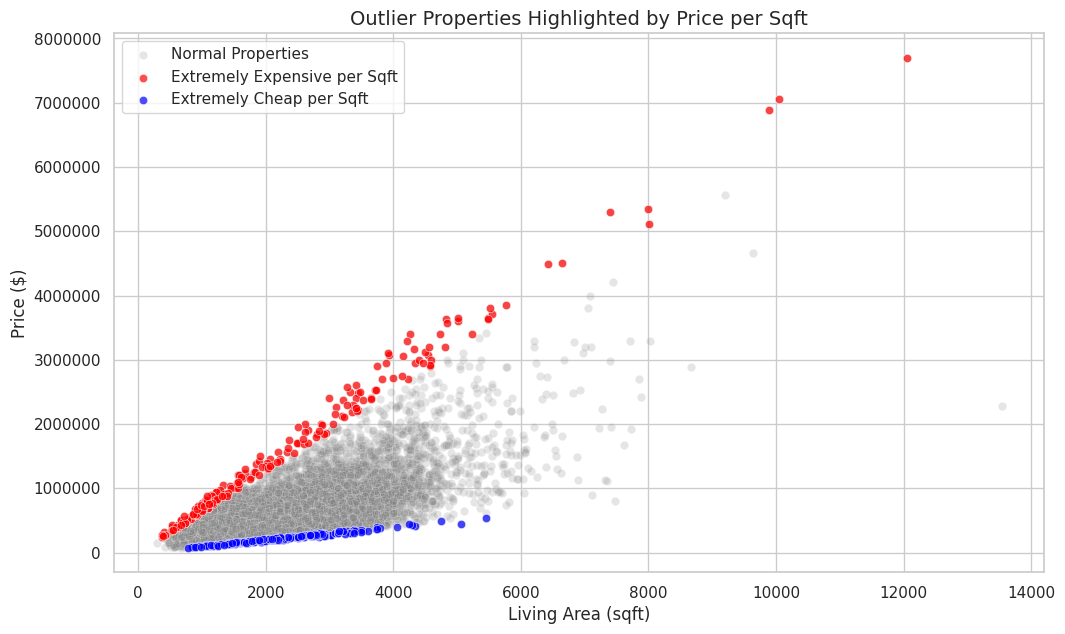

In [6]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x='sqft_living', y='price', alpha=0.2, color='gray', label='Normal Properties')
sns.scatterplot(data=unusual_overpriced, x='sqft_living', y='price', color='red', alpha=0.7, label='Extremely Expensive per Sqft')
sns.scatterplot(data=unusual_underpriced, x='sqft_living', y='price', color='blue', alpha=0.7, label='Extremely Cheap per Sqft')

plt.title('Outlier Properties Highlighted by Price per Sqft', fontsize=14)
plt.xlabel('Living Area (sqft)', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.legend()
plt.ticklabel_format(style='plain', axis='y')
plt.show()

In [7]:
grade_stats = df.groupby('grade')['price'].agg(['count', 'median', 'mean', 'std']).reset_index()
condition_stats = df.groupby('condition')['price'].agg(['count', 'median', 'mean', 'std']).reset_index()

print("Price Statistics by Property Grade:")
display(grade_stats.sort_values(by='grade'))

print("\nPrice Statistics by Property Condition:")
display(condition_stats.sort_values(by='condition'))

Price Statistics by Property Grade:


,grade,count,median,mean,std
0,1,1,142000.0,1.420000e+05,NaN
1,3,3,262000.0,2.056667e+05,1.135180e+05
2,4,29,205000.0,2.143810e+05,9.430617e+04
3,5,242,228700.0,2.485240e+05,1.181003e+05
4,6,2038,275276.5,3.019196e+05,1.229703e+05
5,7,8981,375000.0,4.025903e+05,1.558769e+05
6,8,6068,510000.0,5.428528e+05,2.174734e+05
7,9,2615,720000.0,7.735132e+05,3.161201e+05
8,10,1134,914327.0,1.071771e+06,4.835451e+05
9,11,399,1284000.0,1.496842e+06,7.050993e+05



Price Statistics by Property Condition:


,condition,count,median,mean,std
0,1,30,262500.0,334431.666667,271172.804837
1,2,172,279000.0,327287.145349,245418.413220
2,3,14031,450000.0,542012.578148,364449.062343
3,4,5679,440000.0,521200.390033,358516.231350
4,5,1701,526000.0,612418.089359,410971.922540


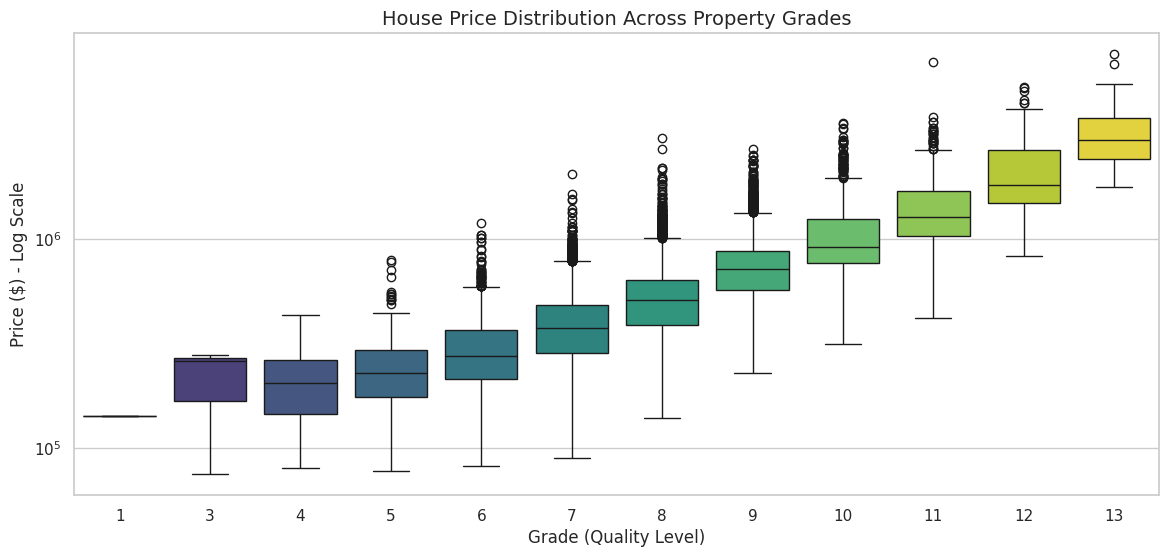

In [8]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='grade', y='price', palette='viridis', hue='grade', legend=False)
plt.title('House Price Distribution Across Property Grades', fontsize=14)
plt.xlabel('Grade (Quality Level)', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.yscale('log')
plt.ylabel('Price ($) - Log Scale', fontsize=12)
plt.show()

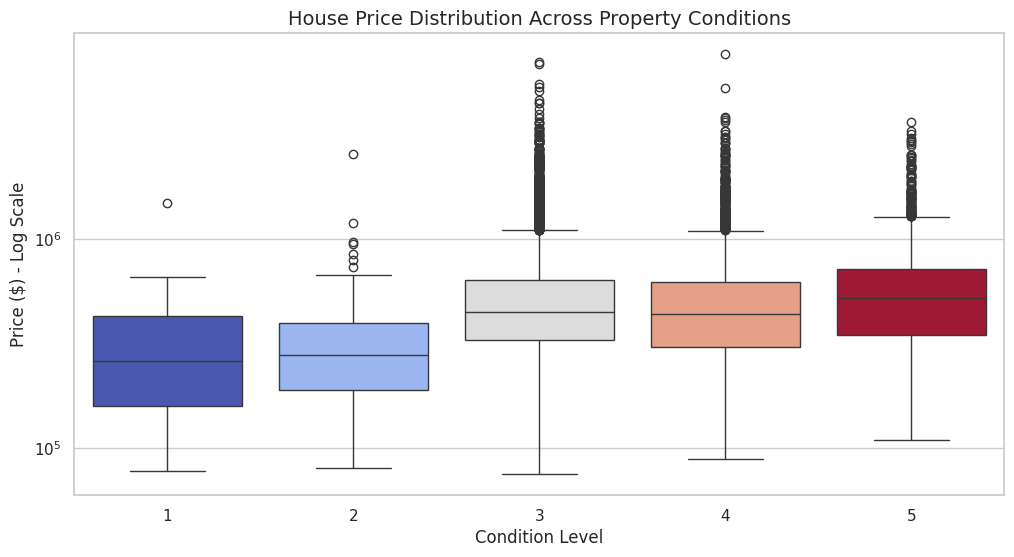

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='condition', y='price', palette='coolwarm', hue='condition', legend=False)
plt.title('House Price Distribution Across Property Conditions', fontsize=14)
plt.xlabel('Condition Level', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.yscale('log')
plt.ylabel('Price ($) - Log Scale', fontsize=12)
plt.show()

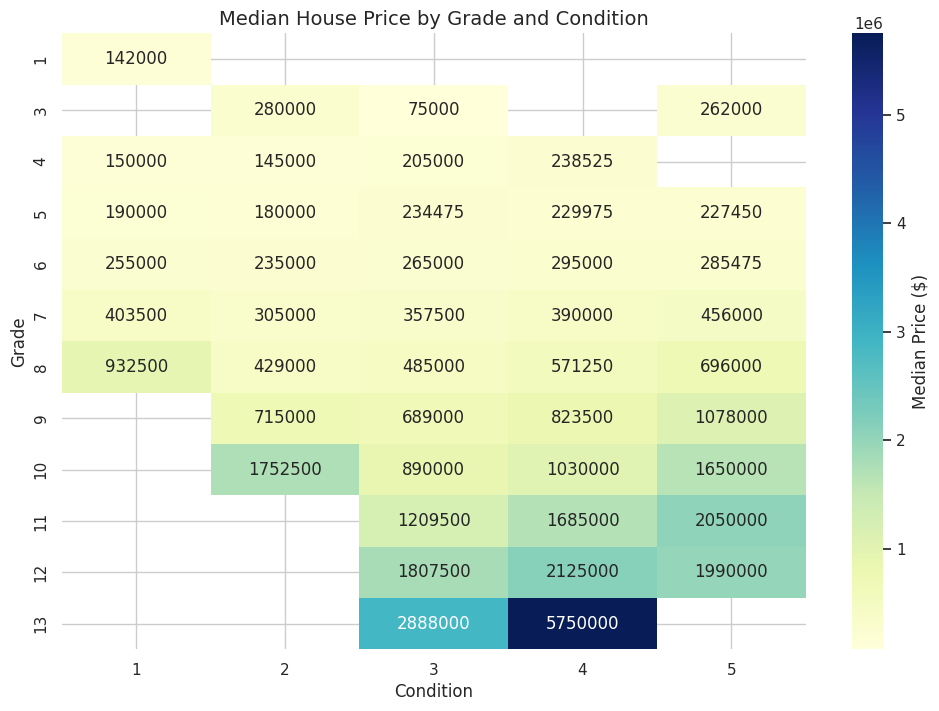

In [10]:
pivot_table = df.pivot_table(values='price', index='grade', columns='condition', aggfunc='median')

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={'label': 'Median Price ($)'})
plt.title('Median House Price by Grade and Condition', fontsize=14)
plt.xlabel('Condition', fontsize=12)
plt.ylabel('Grade', fontsize=12)
plt.show()

Waterfront Price Statistics:


,waterfront,count,median,mean,std
0,0,21450,450000.0,5.315636e+05,3.415996e+05
1,1,163,1400000.0,1.661876e+06,1.120372e+06



Median Price Premium for Waterfront Properties: $950,000.00 (3.11x higher median)


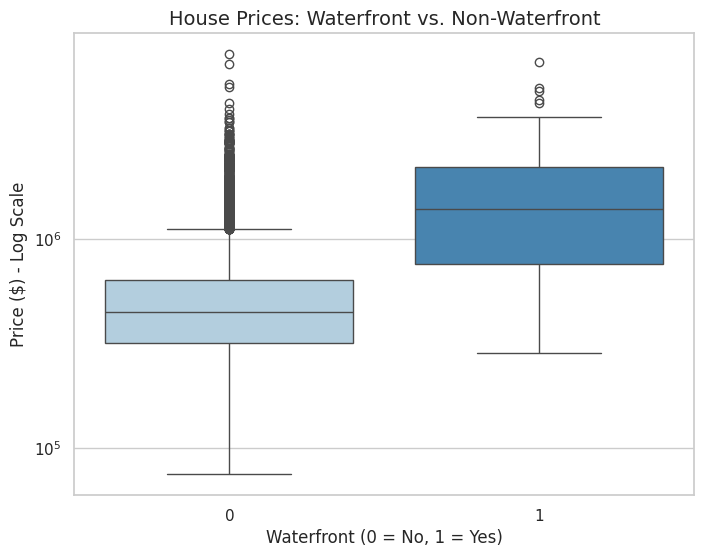

In [11]:
waterfront_stats = df.groupby('waterfront')['price'].agg(['count', 'median', 'mean', 'std']).reset_index()
print("Waterfront Price Statistics:")
display(waterfront_stats)

median_premium = waterfront_stats.loc[1, 'median'] - waterfront_stats.loc[0, 'median']
ratio_premium = waterfront_stats.loc[1, 'median'] / waterfront_stats.loc[0, 'median']
print(f"\nMedian Price Premium for Waterfront Properties: ${median_premium:,.2f} ({ratio_premium:.2f}x higher median)")
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='waterfront', y='price', palette='Blues', hue='waterfront', legend=False)
plt.title('House Prices: Waterfront vs. Non-Waterfront', fontsize=14)
plt.xlabel('Waterfront (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Price ($) - Log Scale', fontsize=12)
plt.yscale('log')
plt.show()

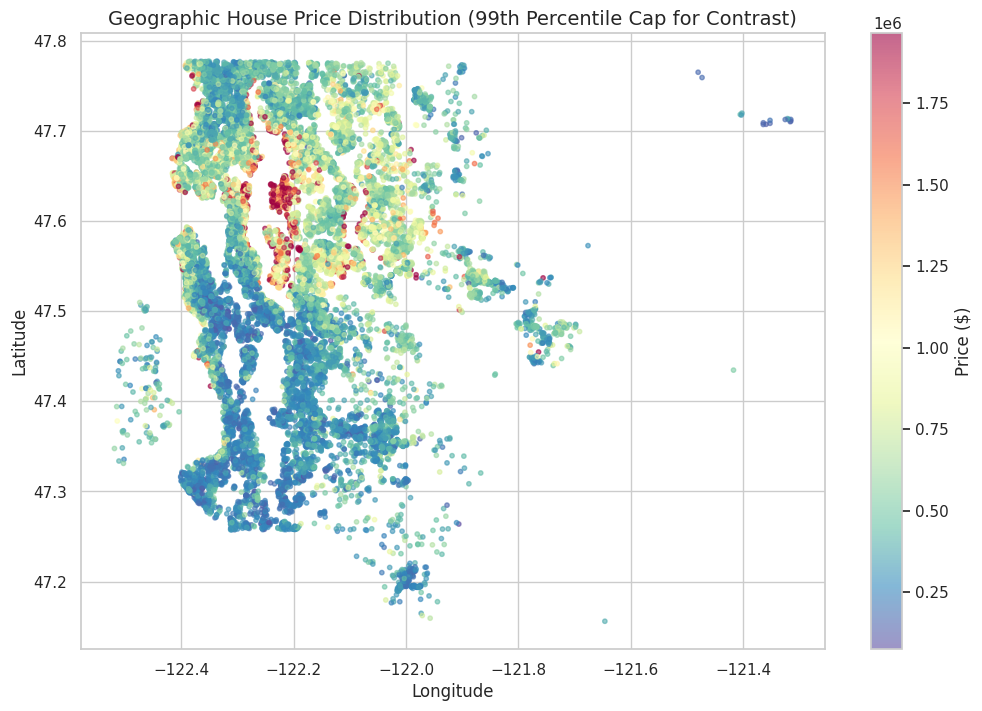

In [12]:

plt.figure(figsize=(12, 8))
scatter = plt.scatter(df['long'], df['lat'], c=df['price'], cmap='Spectral_r', alpha=0.6, s=10, norm=plt.Normalize(df['price'].min(), df['price'].quantile(0.99)))
plt.colorbar(scatter, label='Price ($)')
plt.title('Geographic House Price Distribution (99th Percentile Cap for Contrast)', fontsize=14)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.show()

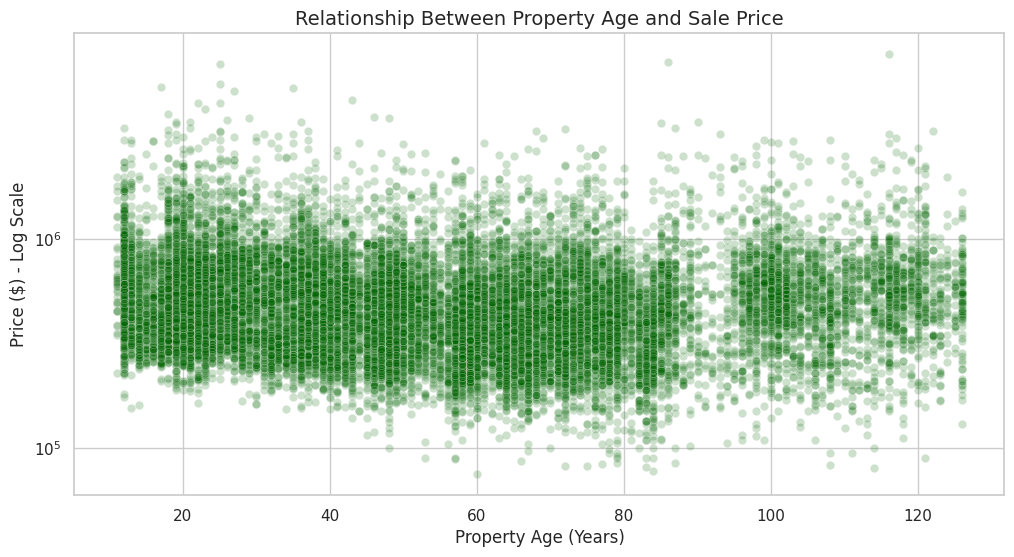

In [13]:
import datetime
current_year = datetime.datetime.now().year

df['property_age'] = current_year - df['yr_built']

df['is_renovated'] = df['yr_renovated'].apply(lambda x: 1 if x > 0 else 0)

df['price_per_sqft_living'] = df['price'] / df['sqft_living']


plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='property_age', y='price', alpha=0.2, color='darkgreen')
plt.title('Relationship Between Property Age and Sale Price', fontsize=14)
plt.xlabel('Property Age (Years)', fontsize=12)
plt.ylabel('Price ($) - Log Scale', fontsize=12)
plt.yscale('log')
plt.show()

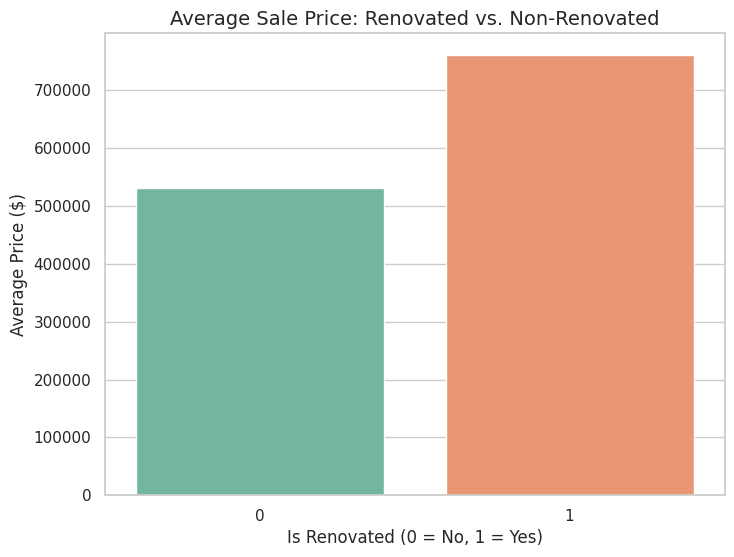

In [14]:
plt.figure(figsize=(8, 6))
sns.barplot(data=df, x='is_renovated', y='price', palette='Set2', errorbar=None, hue='is_renovated', legend=False)
plt.title('Average Sale Price: Renovated vs. Non-Renovated', fontsize=14)
plt.xlabel('Is Renovated (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Average Price ($)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.show()

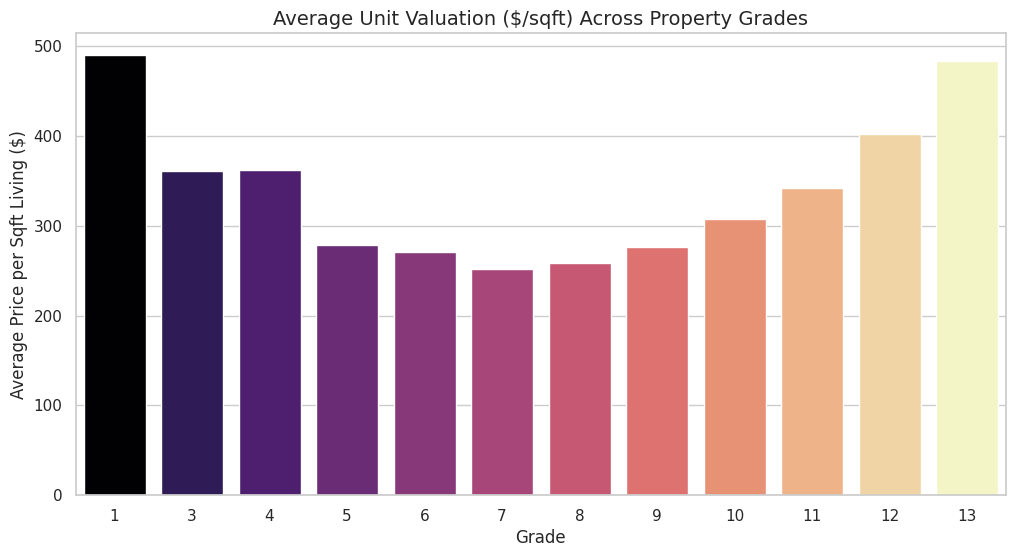

In [15]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='grade', y='price_per_sqft_living', palette='magma', errorbar=None, hue='grade', legend=False)
plt.title('Average Unit Valuation ($/sqft) Across Property Grades', fontsize=14)
plt.xlabel('Grade', fontsize=12)
plt.ylabel('Average Price per Sqft Living ($)', fontsize=12)
plt.show()

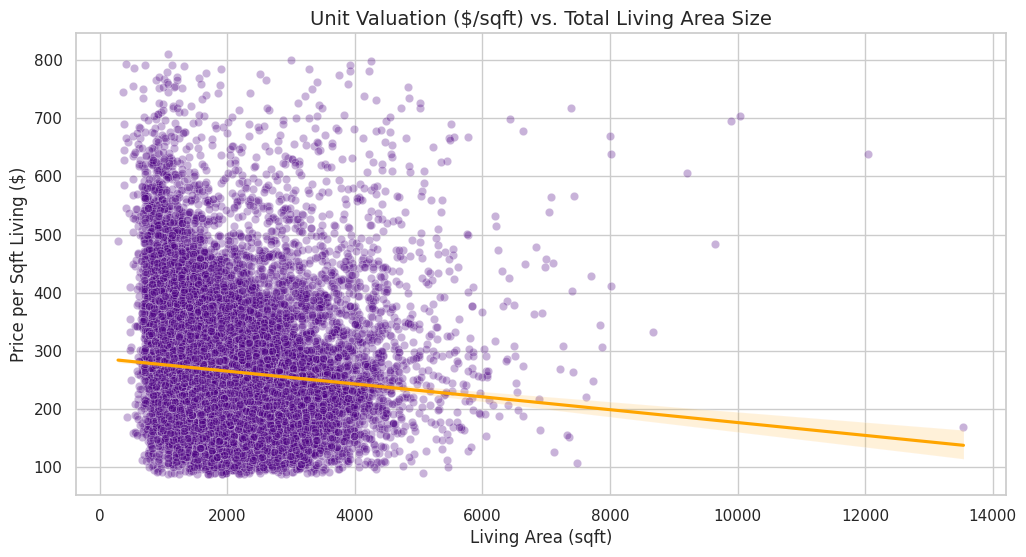

In [16]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='sqft_living', y='price_per_sqft_living', alpha=0.3, color='indigo')
sns.regplot(data=df, x='sqft_living', y='price_per_sqft_living', scatter=False, color='orange')
plt.title('Unit Valuation ($/sqft) vs. Total Living Area Size', fontsize=14)
plt.xlabel('Living Area (sqft)', fontsize=12)
plt.ylabel('Price per Sqft Living ($)', fontsize=12)
plt.show()